In [28]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision .transforms as transforms
import matplotlib . pyplot as plt
import random
import numpy as np

SEED = 42
random.seed(SEED)

In [5]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch:', torch.__version__)
print('Torchvision:', torchvision.__version__)
print('Device:', device)

PyTorch: 2.13.0+cpu
Torchvision: 0.28.0+cpu
Device: cpu


In [ ]:
# 1. Dataloading
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

batch_size = 50
trainset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                        download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                           shuffle=True, num_workers=2)
testset = torchvision.datasets.CIFAR10(root='./data', train=False,
                                       download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size,
                                          shuffle=False, num_workers=2)
classes = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')
print(len(trainset), 'training images;', len(testset), 'test images')


50000 training images; 10000 test images


Epoch 1/10, Loss: 2.3027599267959595
Epoch 2/10, Loss: 2.3027530727386476
Epoch 3/10, Loss: 2.302739901304245
Epoch 4/10, Loss: 2.302739585161209
Epoch 5/10, Loss: 2.302703825235367
Epoch 6/10, Loss: 2.3026990327835084
Epoch 7/10, Loss: 2.3026920478343964
Epoch 8/10, Loss: 2.3026807951927184
Epoch 9/10, Loss: 2.3026751544475554
Epoch 10/10, Loss: 2.3026683435440063


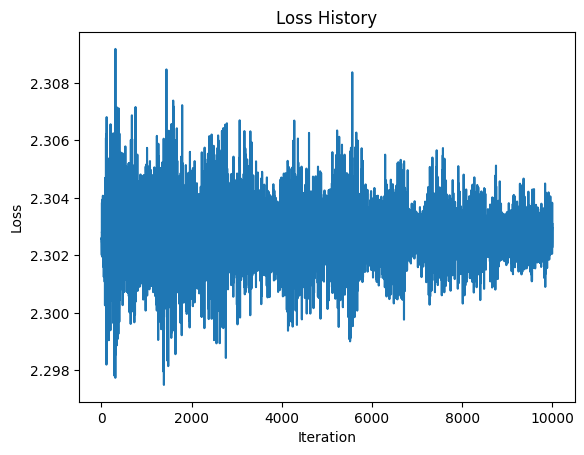

Training accuracy: 10.00%
Test accuracy: 10.00%


In [19]:
# Custom activation and loss functions
def sigmoid(x):
    return 1 / (1 + torch.exp(-x))

def cross_entropy_loss(y_pred, y_true):
    return -torch.sum(y_true * torch.log(y_pred + 1e-9)) / y_true.shape[0]

# 2. Define Network Parameters
Din = 3 * 32 * 32  # Input size (flattened CIFAR-10 image size)
H = 100            # Hidden layer size
K = 10             # Output size (number of classes in CIFAR-10)
std = 1e-5

# Initialize weights and biases
w1 = torch.randn(Din, H) * std
b1 = torch.zeros(H)
w2 = torch.randn(H, K) * std
b2 = torch.zeros(K)

# Hyperparameters
iterations = 10
lr = 1e-3          # Learning rate
lr_decay = 0.9     # Learning rate decay
reg = 0            # Regularization
loss_history = []


# 3. Training Loop
for t in range(iterations):
    running_loss = 0.0

    for i, data in enumerate(trainloader, 0):
        # Get inputs and labels
        inputs, labels = data
        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)
        y_train_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass
        h = sigmoid(x_train.mm(w1) + b1)
        y_pred = h.mm(w2) + b2
        y_pred_softmax = torch.softmax(y_pred, dim=1)

        # Loss calculation (Cross-Entropy with regularization)
        loss = cross_entropy_loss(y_pred_softmax, y_train_onehot) + reg * (torch.sum(w1 ** 2) + torch.sum(w2 ** 2))
        loss_history.append(loss.item())
        running_loss += loss.item()

        # Backpropagation
        dy_pred = (y_pred_softmax - y_train_onehot) / Ntr

        dw2 = h.t().mm(dy_pred) + 2 * reg * w2
        db2 = dy_pred.sum(dim=0)

        dh = dy_pred.mm(w2.t())
        dz = dh * h * (1 - h)

        dw1 = x_train.t().mm(dz) + 2 * reg * w1
        db1 = dz.sum(dim=0)

        # Parameter update
        w1 -= lr * dw1
        b1 -= lr * db1
        w2 -= lr * dw2
        b2 -= lr * db2

    # Print loss for every epoch
    if t % 1 == 0:
        print(f"Epoch {t + 1}/{iterations}, Loss: {running_loss / len(trainloader)}")

    # Learning rate decay
    lr *= lr_decay


# 4. Plotting the Loss History
plt.plot(loss_history)
plt.title("Loss History")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()


# 5. Calculate Accuracy on Training Set
correct_train = 0
total_train = 0

with torch.no_grad():
    for data in trainloader:
        inputs, labels = data
        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)

        # Forward pass
        h = sigmoid(x_train.mm(w1) + b1)
        y_train_pred = h.mm(w2) + b2

        predicted_train = torch.argmax(y_train_pred, dim=1)
        total_train += labels.size(0)
        correct_train += (predicted_train == labels).sum().item()

train_acc = 100 * correct_train / total_train
print(f"Training accuracy: {train_acc:.2f}%")


# 6. Calculate Accuracy on Test Set
correct_test = 0
total_test = 0

with torch.no_grad():
    for data in testloader:
        inputs, labels = data
        Nte = inputs.shape[0]
        x_test = inputs.view(Nte, -1)

        # Forward pass
        h = sigmoid(x_test.mm(w1) + b1)
        y_test_pred = h.mm(w2) + b2

        predicted_test = torch.argmax(y_test_pred, dim=1)
        total_test += labels.size(0)
        correct_test += (predicted_test == labels).sum().item()

test_acc = 100 * correct_test / total_test
print(f"Test accuracy: {test_acc:.2f}%")


In [21]:
mnist_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

mnist_trainset = datasets.MNIST(root='./data', train=True, download=True, transform=mnist_transform)
mnist_testset = datasets.MNIST(root='./data', train=False, download=True, transform=mnist_transform)

mnist_trainloader = DataLoader(mnist_trainset, batch_size=64, shuffle=True,num_workers=2)
mnist_testloader = DataLoader(mnist_testset, batch_size=64, shuffle=False,num_workers=2)

print(len(mnist_trainset), 'training images;', len(mnist_testset), 'test images')

60000 training images; 10000 test images


In [23]:
class LeNet5(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 6, kernel_size=5)    # 28 -> 24
        self.conv2 = nn.Conv2d(6, 16, kernel_size=5)   # 12 -> 8
        self.fc1 = nn.Linear(16 * 4 * 4, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x):
        x = torch.relu(self.conv1(x))
        x = torch.max_pool2d(x, 2)

        x = torch.relu(self.conv2(x))
        x = torch.max_pool2d(x, 2)

        x = torch.flatten(x, 1)
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        return self.fc3(x)

lenet = LeNet5().to(device)


In [24]:
class ModernSmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)
        self.drop2d = nn.Dropout2d(0.25)
        self.fc1 = nn.Linear(128 * 7 * 7, 128)
        self.drop = nn.Dropout(0.5)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = torch.relu(self.bn1(self.conv1(x)))
        x = torch.relu(self.bn2(self.conv2(x)))
        x = nn.MaxPool2d(2, 2)(x)       # 28 -> 14
        x = self.drop2d(x)

        x = torch.relu(self.bn3(self.conv3(x)))
        x = nn.MaxPool2d(2, 2)(x)       # 14 -> 7
        x = self.drop2d(x)

        x = torch.flatten(x, 1)
        x = torch.relu(self.fc1(x))
        x = self.drop(x)
        return self.fc2(x)

modern_cnn = ModernSmallCNN().to(device)


In [27]:
# Train the Model
def train_model(model, optimizer, criterion, train_loader, test_loader, num_epochs=10):
    history = {
        'train_loss': [], 'train_acc': [],
        'test_loss': [], 'test_acc': []
    }

    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)

            # Forward pass
            outputs = model(images)
            loss = criterion(outputs, labels)

            # Backward pass and optimization
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * labels.size(0)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        train_loss = running_loss / total
        train_accuracy = 100 * correct / total

        # Test the model after each epoch
        model.eval()
        test_loss = 0.0
        test_correct = 0
        test_total = 0

        with torch.no_grad():
            for images, labels in test_loader:
                images, labels = images.to(device), labels.to(device)

                outputs = model(images)
                loss = criterion(outputs, labels)

                test_loss += loss.item() * labels.size(0)
                _, predicted = torch.max(outputs, 1)
                test_total += labels.size(0)
                test_correct += (predicted == labels).sum().item()

        test_loss /= test_total
        test_accuracy = 100 * test_correct / test_total

        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_accuracy)
        history['test_loss'].append(test_loss)
        history['test_acc'].append(test_accuracy)

        print(
            f'Epoch [{epoch+1}/{num_epochs}], '
            f'Train Loss: {train_loss:.4f}, '
            f'Train Accuracy: {train_accuracy:.2f}%, '
            f'Test Loss: {test_loss:.4f}, '
            f'Test Accuracy: {test_accuracy:.2f}%'
        )

    return history


# Train LeNet-5
torch.manual_seed(SEED)
lenet = LeNet5().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(lenet.parameters(), lr=0.01, momentum=0.9)

lenet_history = train_model(
    lenet, optimizer, criterion,
    mnist_trainloader, mnist_testloader
)


# Train Modern CNN
torch.manual_seed(SEED)
modern_cnn = ModernSmallCNN().to(device)
optimizer = optim.SGD(modern_cnn.parameters(), lr=0.01, momentum=0.9)

modern_history = train_model(
    modern_cnn, optimizer, criterion,
    mnist_trainloader, mnist_testloader
)


# Final Results
print("\nFinal Results after 10 Epochs")
print(f'LeNet-5 Training Accuracy: {lenet_history["train_acc"][-1]:.2f}%')
print(f'LeNet-5 Test Accuracy: {lenet_history["test_acc"][-1]:.2f}%')
print(f'Modern CNN Training Accuracy: {modern_history["train_acc"][-1]:.2f}%')
print(f'Modern CNN Test Accuracy: {modern_history["test_acc"][-1]:.2f}%')


Epoch [1/10], Train Loss: 0.3057, Train Accuracy: 90.55%, Test Loss: 0.0617, Test Accuracy: 97.95%
Epoch [2/10], Train Loss: 0.0654, Train Accuracy: 97.94%, Test Loss: 0.0460, Test Accuracy: 98.67%
Epoch [3/10], Train Loss: 0.0462, Train Accuracy: 98.54%, Test Loss: 0.0378, Test Accuracy: 98.85%
Epoch [4/10], Train Loss: 0.0361, Train Accuracy: 98.90%, Test Loss: 0.0381, Test Accuracy: 98.89%
Epoch [5/10], Train Loss: 0.0311, Train Accuracy: 99.03%, Test Loss: 0.0352, Test Accuracy: 98.94%
Epoch [6/10], Train Loss: 0.0263, Train Accuracy: 99.16%, Test Loss: 0.0416, Test Accuracy: 98.71%
Epoch [7/10], Train Loss: 0.0215, Train Accuracy: 99.31%, Test Loss: 0.0353, Test Accuracy: 98.90%
Epoch [8/10], Train Loss: 0.0194, Train Accuracy: 99.37%, Test Loss: 0.0370, Test Accuracy: 98.83%
Epoch [9/10], Train Loss: 0.0154, Train Accuracy: 99.49%, Test Loss: 0.0412, Test Accuracy: 98.81%
Epoch [10/10], Train Loss: 0.0143, Train Accuracy: 99.53%, Test Loss: 0.0411, Test Accuracy: 98.80%
Epoch [1/

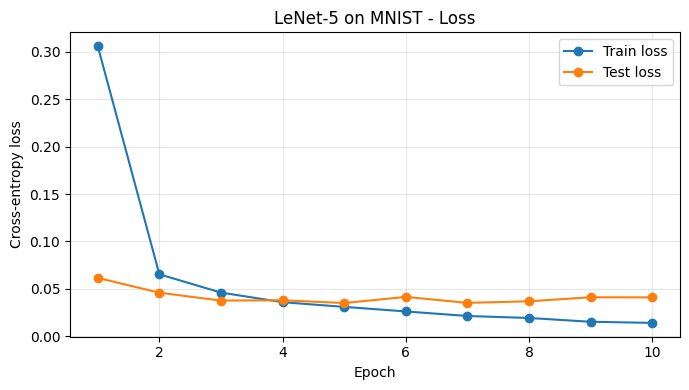

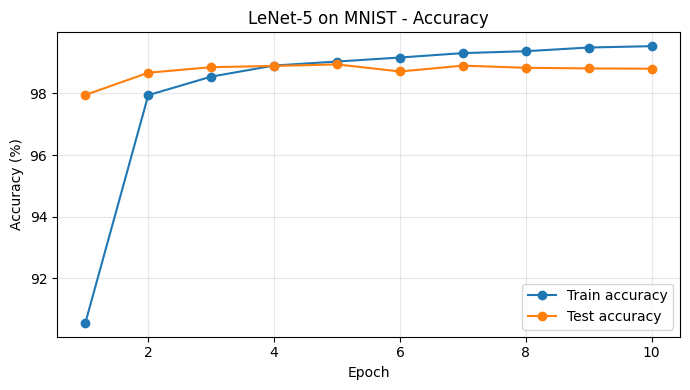

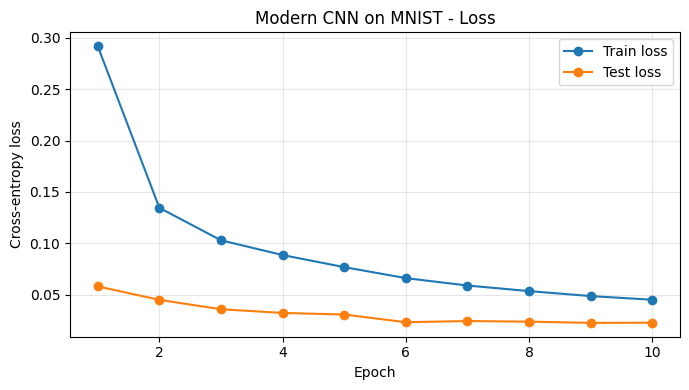

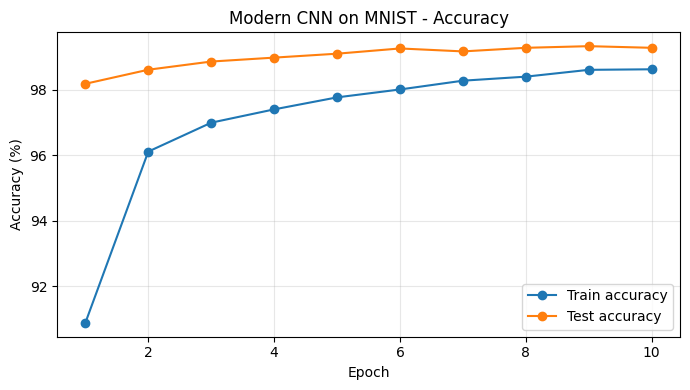

In [29]:
def plot_history(history, model_name, prefix):
    epochs = np.arange(1, len(history['train_loss']) + 1)

    plt.figure(figsize=(7, 4))
    plt.plot(epochs, history['train_loss'], marker='o', label='Train loss')
    plt.plot(epochs, history['test_loss'], marker='o', label='Test loss')
    plt.xlabel('Epoch')
    plt.ylabel('Cross-entropy loss')
    plt.title(f'{model_name} - Loss')
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(7, 4))
    plt.plot(epochs, history['train_acc'], marker='o', label='Train accuracy')
    plt.plot(epochs, history['test_acc'], marker='o', label='Test accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy (%)')
    plt.title(f'{model_name} - Accuracy')
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

plot_history(lenet_history, 'LeNet-5 on MNIST', 'q2_lenet')
plot_history(modern_history, 'Modern CNN on MNIST', 'q2_modern_cnn')


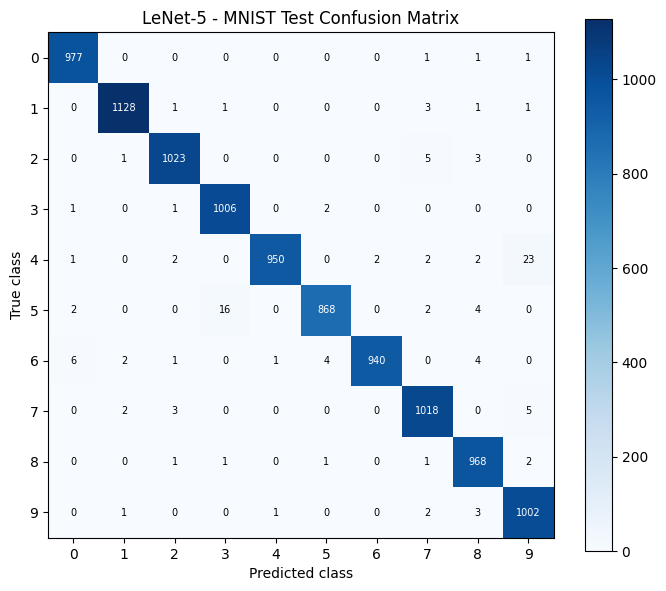

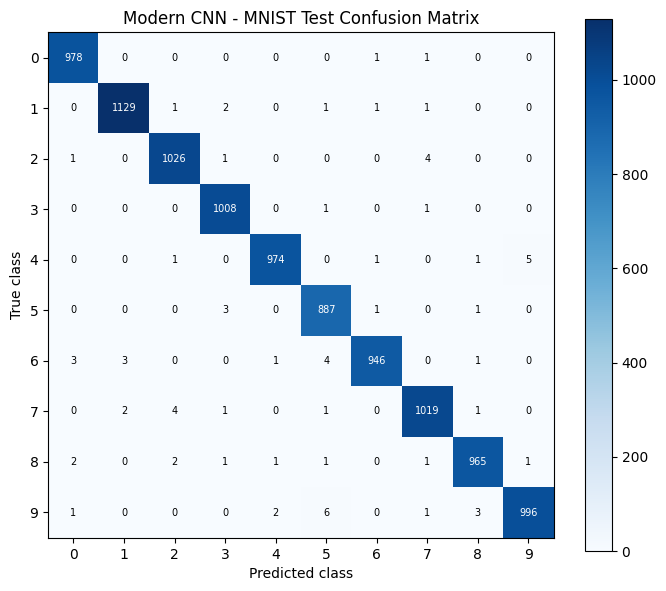

In [30]:
def confusion_matrix_tensor(model, loader, num_classes):
    cm = torch.zeros(num_classes, num_classes, dtype=torch.int64)
    model.eval()
    with torch.no_grad():
        for x, y in loader:
            x = x.to(device)
            pred = model(x).argmax(1).cpu()
            y = y.cpu()
            for true, guessed in zip(y, pred):
                cm[true.long(), guessed.long()] += 1
    return cm.numpy()


def plot_confusion_matrix(cm, labels, title, filename):
    plt.figure(figsize=(7, 6))
    plt.imshow(cm, interpolation='nearest', cmap='Blues')
    plt.title(title)
    plt.colorbar()
    ticks = np.arange(len(labels))
    plt.xticks(ticks, labels)
    plt.yticks(ticks, labels)
    plt.xlabel('Predicted class')
    plt.ylabel('True class')
    threshold = cm.max() / 2.0
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            plt.text(j, i, str(cm[i, j]), ha='center', va='center',
                     color='white' if cm[i, j] > threshold else 'black', fontsize=7)
    plt.tight_layout()
    plt.show()

lenet_cm = confusion_matrix_tensor(lenet, mnist_testloader, 10)
modern_cm = confusion_matrix_tensor(modern_cnn, mnist_testloader, 10)

plot_confusion_matrix(lenet_cm, list(range(10)), 'LeNet-5 - MNIST Test Confusion Matrix', 'q2_lenet_confusion.png')
plot_confusion_matrix(modern_cm, list(range(10)), 'Modern CNN - MNIST Test Confusion Matrix', 'q2_modern_confusion.png')
